In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.io import imread
from skimage.transform import resize
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score
)

from skimage import io, color
from sklearn.preprocessing import MinMaxScaler
import skfuzzy as fuzz


In [2]:
from sklearn.preprocessing import MinMaxScaler

categories = ['Diseased', 'Healthy']

train_dir = '..\\Augmentation\\Augmented DataSet\\Train'
test_dir  = '..\\Augmentation\\Augmented DataSet\\Test'


def load_raw(base_dir, categories):
    features = []
    labels = []

    for label_idx, cat in enumerate(categories):
        folder = os.path.join(base_dir, cat)
        print(f'Loading {cat} from {base_dir}')

        for fname in os.listdir(folder):
            img = imread(os.path.join(folder, fname))
            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            gray = cv2.GaussianBlur(gray, (7, 7), 0)
            resized = resize(gray, (64, 64))
            features.append(resized.flatten())
            labels.append(label_idx)

        print(f'Done: {cat}')

    return np.array(features), np.array(labels)


X_train_raw, y_train = load_raw(train_dir, categories)
X_test_raw,  y_test  = load_raw(test_dir, categories)


Loading Diseased from ..\Augmentation\Augmented DataSet\Train
Done: Diseased
Loading Healthy from ..\Augmentation\Augmented DataSet\Train
Done: Healthy
Loading Diseased from ..\Augmentation\Augmented DataSet\Test
Done: Diseased
Loading Healthy from ..\Augmentation\Augmented DataSet\Test
Done: Healthy


### Fuzzy C-Means

In [3]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled  = scaler.transform(X_test_raw)

# Fuzzy C-Means — fit on train, predict on test
n_clusters = len(categories)
cntr, u_train, _, _, _, _, _ = fuzz.cluster.cmeans(
    X_train_scaled.T, n_clusters, 2.0, maxiter=100, error=0.005
)
u_test, _, _, _, _, _ = fuzz.cluster.cmeans_predict(
    X_test_scaled.T, cntr, 2.0, maxiter=100, error=0.005
)

# FCM membership as extra features, stacked onto raw pixels
X_train = np.hstack([X_train_raw, u_train.T])
X_test  = np.hstack([X_test_raw,  u_test.T])

print("Training Shape :", X_train.shape)
print("Testing Shape  :", X_test.shape)

Training Shape : (5600, 4098)
Testing Shape  : (1400, 4098)


In [4]:
print("Training Samples :", len(X_train))
print("Testing Samples  :", len(X_test))

Training Samples : 5600
Testing Samples  : 1400


In [5]:
def assess_model(name, clf, X_tr, y_tr, X_te, y_te, label_names):
    y_pred = clf.predict(X_te)
    acc  = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred, average='weighted')
    rec  = recall_score(y_te, y_pred, average='weighted')
    f1   = f1_score(y_te, y_pred, average='weighted')
    tr_acc = accuracy_score(y_tr, clf.predict(X_tr))

    print(f'{name}')
    print(classification_report(y_te, y_pred, target_names=label_names))
    print(f'  Test Accuracy  : {acc*100:.2f}%')
    print(f'  Train Accuracy : {tr_acc*100:.2f}%')
    print(f'  Precision      : {prec*100:.2f}%')
    print(f'  Recall         : {rec*100:.2f}%')
    print(f'  F1-Score       : {f1*100:.2f}%')

    cm = confusion_matrix(y_te, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm / cm.sum(), annot=True, fmt='.2%',
                cmap='YlOrRd', xticklabels=label_names, yticklabels=label_names)
    plt.title(f'{name} — Confusion Matrix')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()

    return acc, prec, rec, f1


### Decision Tree

Decision Tree
              precision    recall  f1-score   support

    Diseased       0.81      0.80      0.81       700
     Healthy       0.80      0.82      0.81       700

    accuracy                           0.81      1400
   macro avg       0.81      0.81      0.81      1400
weighted avg       0.81      0.81      0.81      1400

  Test Accuracy  : 80.71%
  Train Accuracy : 99.82%
  Precision      : 80.72%
  Recall         : 80.71%
  F1-Score       : 80.71%


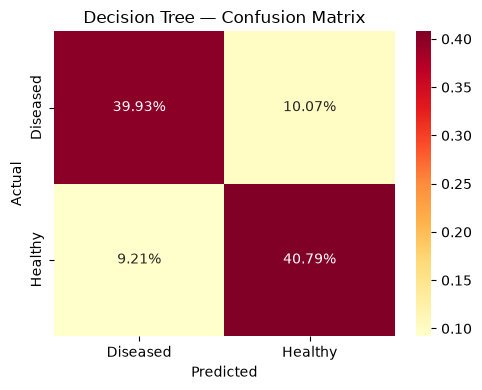

In [6]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=25, random_state=42)
dt.fit(X_train, y_train)
acc_dt, prec_dt, rec_dt, f1_dt = assess_model('Decision Tree', dt, X_train, y_train, X_test, y_test, ['Diseased', 'Healthy'])

### Naive Bayes

Naive Bayes
              precision    recall  f1-score   support

    Diseased       0.88      0.84      0.86       700
     Healthy       0.85      0.89      0.87       700

    accuracy                           0.86      1400
   macro avg       0.86      0.86      0.86      1400
weighted avg       0.86      0.86      0.86      1400

  Test Accuracy  : 86.29%
  Train Accuracy : 88.70%
  Precision      : 86.38%
  Recall         : 86.29%
  F1-Score       : 86.28%


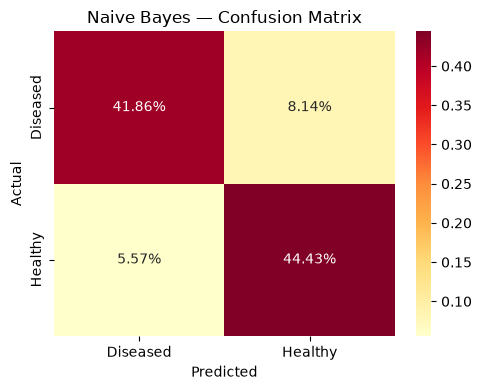

In [7]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)
acc_nb, prec_nb, rec_nb, f1_nb = assess_model('Naive Bayes', nb, X_train, y_train, X_test, y_test, ['Diseased', 'Healthy'])

### Logistic Regression

Logistic Regression
              precision    recall  f1-score   support

    Diseased       0.86      0.77      0.81       700
     Healthy       0.79      0.87      0.83       700

    accuracy                           0.82      1400
   macro avg       0.82      0.82      0.82      1400
weighted avg       0.82      0.82      0.82      1400

  Test Accuracy  : 82.00%
  Train Accuracy : 89.96%
  Precision      : 82.34%
  Recall         : 82.00%
  F1-Score       : 81.95%


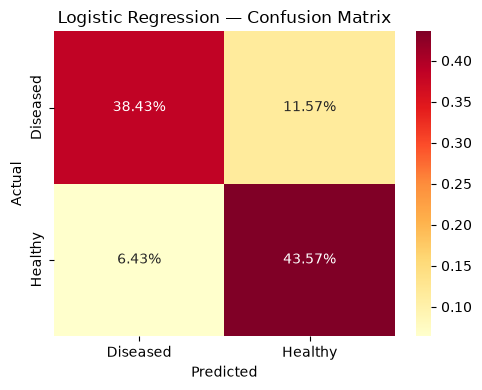

In [8]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(solver='liblinear', random_state=42)
lr.fit(X_train, y_train)
acc_lr, prec_lr, rec_lr, f1_lr = assess_model('Logistic Regression', lr, X_train, y_train, X_test, y_test, ['Diseased', 'Healthy'])

### K-Nearest Neighbors

KNN
              precision    recall  f1-score   support

    Diseased       0.97      0.47      0.63       700
     Healthy       0.65      0.98      0.78       700

    accuracy                           0.72      1400
   macro avg       0.81      0.72      0.71      1400
weighted avg       0.81      0.72      0.71      1400

  Test Accuracy  : 72.50%
  Train Accuracy : 76.93%
  Precision      : 80.78%
  Recall         : 72.50%
  F1-Score       : 70.52%


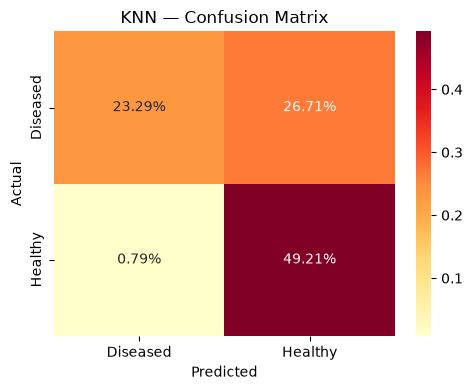

In [9]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(X_train, y_train)
acc_knn, prec_knn, rec_knn, f1_knn = assess_model('KNN', knn, X_train, y_train, X_test, y_test, ['Diseased', 'Healthy'])

### Random Forest

Random Forest
              precision    recall  f1-score   support

    Diseased       0.88      0.93      0.91       700
     Healthy       0.93      0.88      0.90       700

    accuracy                           0.90      1400
   macro avg       0.90      0.90      0.90      1400
weighted avg       0.90      0.90      0.90      1400

  Test Accuracy  : 90.36%
  Train Accuracy : 96.93%
  Precision      : 90.48%
  Recall         : 90.36%
  F1-Score       : 90.35%


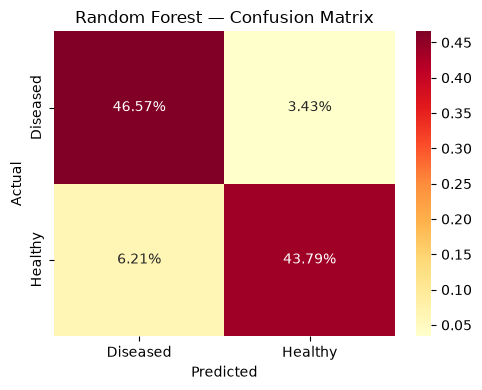

In [10]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, min_samples_split=12,
                             min_samples_leaf=5, max_features='log2', random_state=42)
rf.fit(X_train, y_train)
acc_rf, prec_rf, rec_rf, f1_rf = assess_model('Random Forest', rf, X_train, y_train, X_test, y_test, ['Diseased', 'Healthy'])

### Voting Classifiers

Soft Voting
              precision    recall  f1-score   support

    Diseased       0.90      0.81      0.85       700
     Healthy       0.83      0.91      0.87       700

    accuracy                           0.86      1400
   macro avg       0.87      0.86      0.86      1400
weighted avg       0.87      0.86      0.86      1400

  Test Accuracy  : 86.14%
  Train Accuracy : 94.98%
  Precision      : 86.51%
  Recall         : 86.14%
  F1-Score       : 86.11%


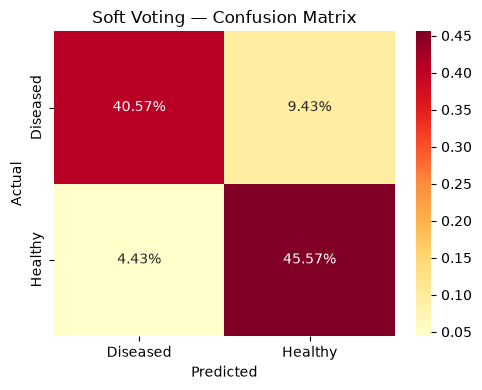

Hard Voting
              precision    recall  f1-score   support

    Diseased       0.87      0.85      0.86       700
     Healthy       0.86      0.87      0.87       700

    accuracy                           0.86      1400
   macro avg       0.86      0.86      0.86      1400
weighted avg       0.86      0.86      0.86      1400

  Test Accuracy  : 86.43%
  Train Accuracy : 94.32%
  Precision      : 86.44%
  Recall         : 86.43%
  F1-Score       : 86.43%


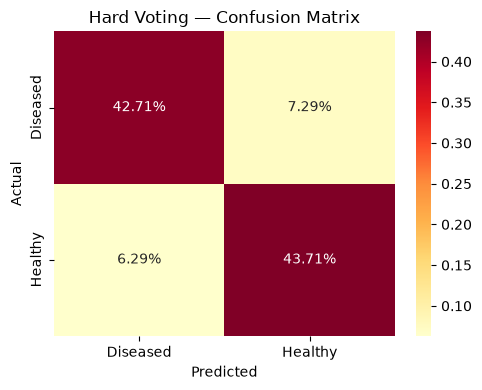

In [11]:
from sklearn.ensemble import VotingClassifier

estimators = [('nb', nb), ('dt', dt), ('knn', knn), ('lr', lr)]

soft_vc = VotingClassifier(estimators=estimators, voting='soft')
soft_vc.fit(X_train, y_train)
acc_sv, prec_sv, rec_sv, f1_sv = assess_model('Soft Voting', soft_vc, X_train, y_train, X_test, y_test, ['Diseased', 'Healthy'])

hard_vc = VotingClassifier(estimators=estimators, voting='hard')
hard_vc.fit(X_train, y_train)
acc_hv, prec_hv, rec_hv, f1_hv = assess_model('Hard Voting', hard_vc, X_train, y_train, X_test, y_test, ['Diseased', 'Healthy'])

### Comparison

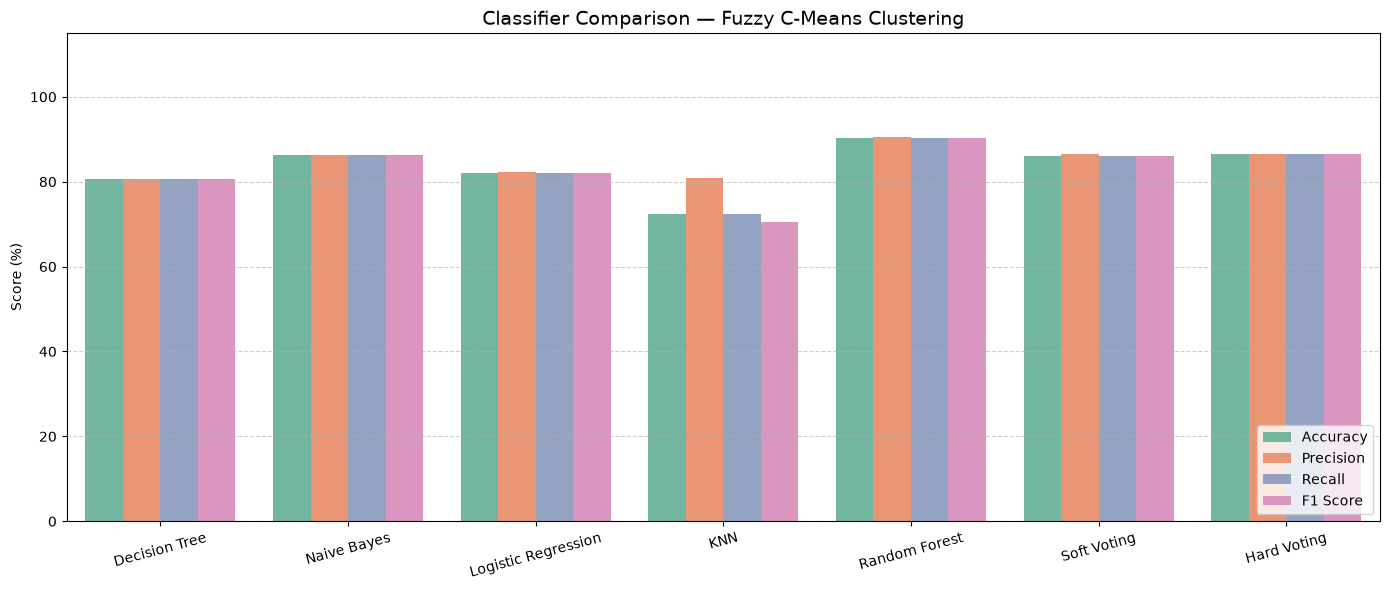

In [12]:
model_names = ['Decision Tree', 'Naive Bayes', 'Logistic Regression', 'KNN', 'Random Forest', 'Soft Voting', 'Hard Voting']
accs  = [acc_dt,  acc_nb,  acc_lr,  acc_knn,  acc_rf,  acc_sv,  acc_hv]
precs = [prec_dt, prec_nb, prec_lr, prec_knn, prec_rf, prec_sv, prec_hv]
recs  = [rec_dt,  rec_nb,  rec_lr,  rec_knn,  rec_rf,  rec_sv,  rec_hv]
f1s   = [f1_dt,   f1_nb,   f1_lr,   f1_knn,   f1_rf,   f1_sv,   f1_hv]

df_cmp = pd.DataFrame({
    'Classifier': model_names,
    'Accuracy': accs, 'Precision': precs,
    'Recall': recs, 'F1 Score': f1s
})
df_melt = df_cmp.melt(id_vars='Classifier', var_name='Metric', value_name='Score')
df_melt['Score'] *= 100

plt.figure(figsize=(14, 6))
sns.barplot(x='Classifier', y='Score', hue='Metric', data=df_melt, palette='Set2')
plt.title('Classifier Comparison — Fuzzy C-Means Clustering', fontsize=14)
plt.ylabel('Score (%)')
plt.xlabel('')
plt.ylim(0, 115)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Live Prediction 

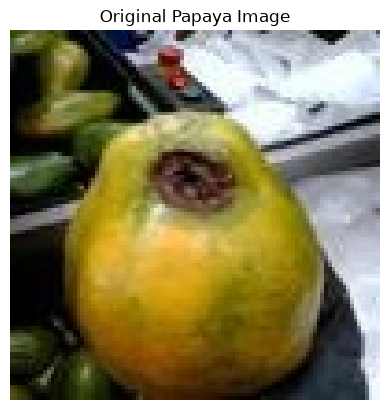

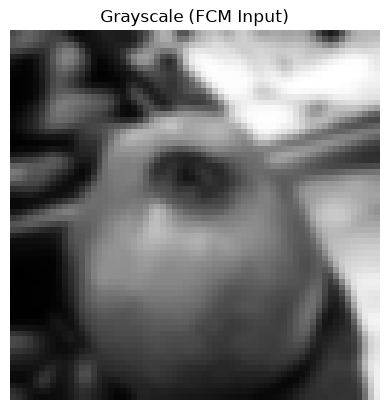

Prediction Probabilities:
Diseased: 91.81%
Healthy: 8.19%

Final Prediction: The Disease image is classified as Diseased


In [13]:
import random
categories = ['Diseased', 'Healthy']

sample_dir = os.path.join(test_dir, 'Diseased')
sample_file = random.choice(os.listdir(sample_dir))
sample_path = os.path.join(sample_dir, sample_file)

sample_img = imread(sample_path)

plt.imshow(sample_img)
plt.axis('off')
plt.title('Original Papaya Image')
plt.show()


gray_sample = cv2.cvtColor(sample_img, cv2.COLOR_BGR2GRAY)
blurred_sample = cv2.GaussianBlur(gray_sample, (7, 7), 0)
resized_sample = resize(blurred_sample, (64, 64))


plt.imshow(resized_sample, cmap='gray')
plt.axis('off')
plt.title('Grayscale (FCM Input)')
plt.show()

# Raw pixel vector
raw_vec = resized_sample.flatten().reshape(1, -1)

# Scale using the SAME scaler fit on X_train_raw
scaled_vec = scaler.transform(raw_vec)

# Get FCM membership using the SAME cluster centers
u_sample, _, _, _, _, _ = fuzz.cluster.cmeans_predict(
    scaled_vec.T, cntr, 2.0, maxiter=100, error=0.005
)

# Stack raw pixels + FCM membership
prediction_input = np.hstack([raw_vec, u_sample.T])

predicted_idx = rf.predict(prediction_input)[0]  
probabilities = rf.predict_proba(prediction_input)[0]

print("Prediction Probabilities:")
for idx, cat_name in enumerate(categories):
    print(f"{cat_name}: {probabilities[idx] * 100:.2f}%")

print(f"\nFinal Prediction: The Disease image is classified as {categories[predicted_idx]}")